<a href="https://colab.research.google.com/github/kalyanisingh19196-netizen/Neural-Networks-and-Deep-Learning-Lab/blob/main/Assignment-2-MLP-Backpropagation/mlp_numpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch: 2000 Loss: 0.00271
Epoch: 4000 Loss: 0.00126
Epoch: 6000 Loss: 0.00082
Epoch: 8000 Loss: 0.00061
Epoch: 10000 Loss: 0.00048

Final XOR Predictions:
Input: [0 0] Expected: 0 Predicted: 0
Input: [0 1] Expected: 1 Predicted: 1
Input: [1 0] Expected: 1 Predicted: 1
Input: [1 1] Expected: 0 Predicted: 0

Final Accuracy: 100.0 %


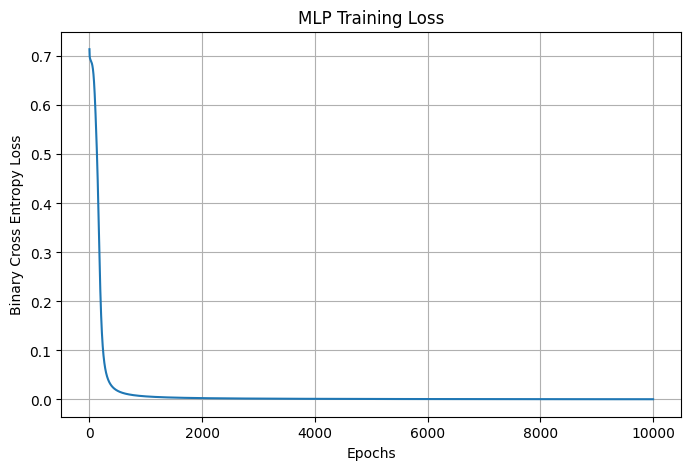

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# XOR Dataset
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([
    [0],
    [1],
    [1],
    [0]
])

# Activation functions
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

def sigmoid_derivative(x):
    return x * (1 - x)

def tanh_derivative(x):
    return 1 - x**2


# Initialize weights
np.random.seed(42)

input_size = 2
hidden_size = 4
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * 0.5
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.5
b2 = np.zeros((1, output_size))

learning_rate = 0.5
epochs = 10000

loss_history = []

# Training loop
for epoch in range(epochs):

    # FORWARD PROPAGATION

    Z1 = np.dot(X, W1) + b1
    A1 = np.tanh(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)

    # Calculate binary cross entropy loss
    epsilon = 1e-8

    loss = -np.mean(
        y * np.log(A2 + epsilon) +
        (1-y) * np.log(1-A2 + epsilon)
    )

    loss_history.append(loss)

    # BACKPROPAGATION

    dZ2 = A2 - y
    dW2 = np.dot(A1.T, dZ2) / len(X)
    db2 = np.mean(dZ2, axis=0, keepdims=True)

    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * tanh_derivative(A1)

    dW1 = np.dot(X.T, dZ1) / len(X)
    db1 = np.mean(dZ1, axis=0, keepdims=True)

    # UPDATE WEIGHTS

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    if (epoch + 1) % 2000 == 0:
        print("Epoch:", epoch + 1, "Loss:", round(loss, 5))


# Final predictions
print("\nFinal XOR Predictions:")

predictions = (A2 >= 0.5).astype(int)

for i in range(len(X)):
    print(
        "Input:", X[i],
        "Expected:", y[i][0],
        "Predicted:", predictions[i][0]
    )

accuracy = np.mean(predictions == y) * 100

print("\nFinal Accuracy:", accuracy, "%")


# Plot training loss
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("MLP Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross Entropy Loss")
plt.grid(True)
plt.show()

##Observations and Conclusion

1. The MLP consists of an input layer, one hidden layer and an output layer.
2. Tanh is used in the hidden layer.
3. Sigmoid is used in the output layer.
4. Forward propagation calculates the network predictions.
5. Backpropagation calculates gradients and updates weights.
6. The training loss decreases as the network learns.
7. The hidden layer enables the network to learn the non-linear XOR relationship.

Conclusion

A Multilayer Perceptron with backpropagation can solve the XOR problem, unlike a single-layer perceptron. Hidden layers enable neural networks to learn non-linear relationships.

##